# Eigenvalue Stability Analysis — Routh-Hurwitz (Linear ODE)
**Author:** Achyutan Veeraraghavan
**Mentor:** Dr. Padmanabhan Seshaiyer (George Mason University)

## Model overview
Four-compartment **LINEAR** ODE system (N, L, M, H). Stability is analyzed as a function of the composite control $\alpha_w$ using the Routh-Hurwitz criterion (slides 7–8).

| Compartment | Meaning |
|---|---|
| $N(t)$ | No risk (protected via education) |
| $L(t)$ | Low risk (susceptible) |
| $M(t)$ | Medium risk |
| $H(t)$ | High risk |

**Control:** composite intervention intensity $\alpha_w$, decomposed with fixed weights into $\alpha = v_\alpha\alpha_w,\quad \gamma_1 = v_1\alpha_w,\quad \gamma_2 = v_2\alpha_w$.

$$\frac{dN}{dt} = \alpha L - \delta N \qquad \frac{dL}{dt} = -\beta_1 L + \gamma_1 M - \alpha L + \delta N$$
$$\frac{dM}{dt} = \beta_1 L - \beta_2 M - \gamma_1 M + \gamma_2 H \qquad \frac{dH}{dt} = \beta_2 M - \gamma_2 H$$

Because the ODEs are linear, the Jacobian is **constant** (the same at every equilibrium).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Section 1 — Parameters

In [2]:
# =============================================================================
# PARAMETERS
# =============================================================================
beta1   = 0.15
beta2   = 0.10
delta   = 0.02
v_alpha = 0.40
v1      = 0.35
v2      = 0.25
alpha_max = 1.0

alpha_w  = np.linspace(0, alpha_max, 2000)
alpha_t  = v_alpha * alpha_w
gamma1_t = v1      * alpha_w
gamma2_t = v2      * alpha_w

## Section 2 — Jacobian and characteristic polynomial (slide 7)

$$J = \begin{pmatrix} -\delta & \alpha & 0 & 0\\ \delta & -\beta_1-\alpha & \gamma_1 & 0\\ 0 & \beta_1 & -\beta_2-\gamma_1 & \gamma_2\\ 0 & 0 & \beta_2 & -\gamma_2 \end{pmatrix}$$

$$\det(\lambda_e I - J) = \lambda_e^4 + A_1\lambda_e^3 + A_2\lambda_e^2 + A_3\lambda_e + A_4 = 0$$

$A_4 = 0$, so $\lambda_{e1} = 0$ (mass conservation). The other three satisfy $\lambda_e^3 + A_1\lambda_e^2 + A_2\lambda_e + A_3 = 0$, with

$$A_1 = \delta + \alpha + \beta_1 + \beta_2 + \gamma_1 + \gamma_2$$
$$A_2 = (\delta+\alpha)(\beta_2+\gamma_1) + \beta_1\beta_2 + \beta_1\delta + \gamma_2(\delta+\alpha+\beta_1+\gamma_1)$$
$$A_3 = \gamma_1\gamma_2(\delta+\alpha) + \beta_1\delta(\beta_2+\gamma_2)$$

**Routh-Hurwitz conditions** (all must hold for every non-zero eigenvalue to have $\mathrm{Re}(\lambda_e) < 0$):

1. $A_1 > 0$
2. $A_2 > 0$
3. $A_3 > 0$
4. $A_1A_2 - A_3 > 0$

In [3]:
# =============================================================================
# ROUTH-HURWITZ COEFFICIENTS (from linear Jacobian directly)
# =============================================================================
A1 = alpha_t + delta + beta1 + beta2 + gamma1_t + gamma2_t

A2 = ((alpha_t + delta) * (beta2 + gamma1_t)
      + beta1 * beta2
      + beta1 * delta
      + gamma2_t * (alpha_t + delta + beta1 + gamma1_t))

A3 = gamma1_t * gamma2_t * (alpha_t + delta) + delta * beta1 * (beta2 + gamma2_t)

RH4 = A1 * A2 - A3

## Section 3 — Numerical eigenvalues (reference check)

In [4]:
# Eigenvalues computed numerically at key alpha_w values for reference
def compute_eigenvalues(aw):
    a  = v_alpha * aw
    g1 = v1 * aw
    g2 = v2 * aw
    J = np.array([
        [-delta,          a,            0,       0   ],
        [ delta,  -(a+beta1),          g1,       0   ],
        [     0,      beta1,  -(beta2+g1),      g2   ],
        [     0,          0,       beta2,       -g2  ]
    ])
    return np.sort(np.real(np.linalg.eigvals(J)))

eigs_0   = compute_eigenvalues(0.001)
eigs_max = compute_eigenvalues(alpha_max)

## Section 4 — Results

In [5]:
# =============================================================================
# PRINT KEY RESULTS
# =============================================================================
print("=" * 60)
print("LINEAR MODEL — ROUTH-HURWITZ STABILITY RESULTS")
print("=" * 60)
for label, idx, eigs in [("α_w = 0.0", 0, eigs_0), ("α_w = 1.0", -1, eigs_max)]:
    print(f"\nAt {label}:")
    print(f"  A1        = {A1[0 if idx==0 else -1]:.4f}  {'> 0 ✓' if A1[0 if idx==0 else -1]>0 else '≤ 0 ✗'}")
    print(f"  A2        = {A2[0 if idx==0 else -1]:.6f}  {'> 0 ✓' if A2[0 if idx==0 else -1]>0 else '≤ 0 ✗'}")
    print(f"  A3        = {A3[0 if idx==0 else -1]:.6f}  {'> 0 ✓' if A3[0 if idx==0 else -1]>0 else '≤ 0 ✗'}")
    print(f"  A1*A2-A3  = {RH4[0 if idx==0 else -1]:.6f}  {'> 0 ✓' if RH4[0 if idx==0 else -1]>0 else '≤ 0 ✗'}")
    print(f"  Eigenvalues (numerical ref): {eigs}")
all_stable = np.all([A1>0, A2>0, A3>0, RH4>0], axis=0)
aw_stable  = alpha_w[all_stable][0] if np.any(all_stable) else None
print(f"\nAll RH conditions first satisfied at α_w = {aw_stable}")
if aw_stable is not None and aw_stable < 1e-6:
    print("  -> System is STABLE for ALL positive α_w values.")

LINEAR MODEL — ROUTH-HURWITZ STABILITY RESULTS

At α_w = 0.0:
  A1        = 0.2700  > 0 ✓
  A2        = 0.020000  > 0 ✓
  A3        = 0.000300  > 0 ✓
  A1*A2-A3  = 0.005100  > 0 ✓
  Eigenvalues (numerical ref): [-1.51490748e-01 -9.95708760e-02 -1.99383757e-02  7.76188128e-20]

At α_w = 1.0:
  A1        = 1.2700  > 0 ✓
  A2        = 0.437000  > 0 ✓
  A3        = 0.037800  > 0 ✓
  A1*A2-A3  = 0.517190  > 0 ✓
  Eigenvalues (numerical ref): [-7.61064554e-01 -3.77295042e-01 -1.31640404e-01  7.20079649e-17]

All RH conditions first satisfied at α_w = 0.0
  -> System is STABLE for ALL positive α_w values.


## Section 5 — Figure (slide 8)

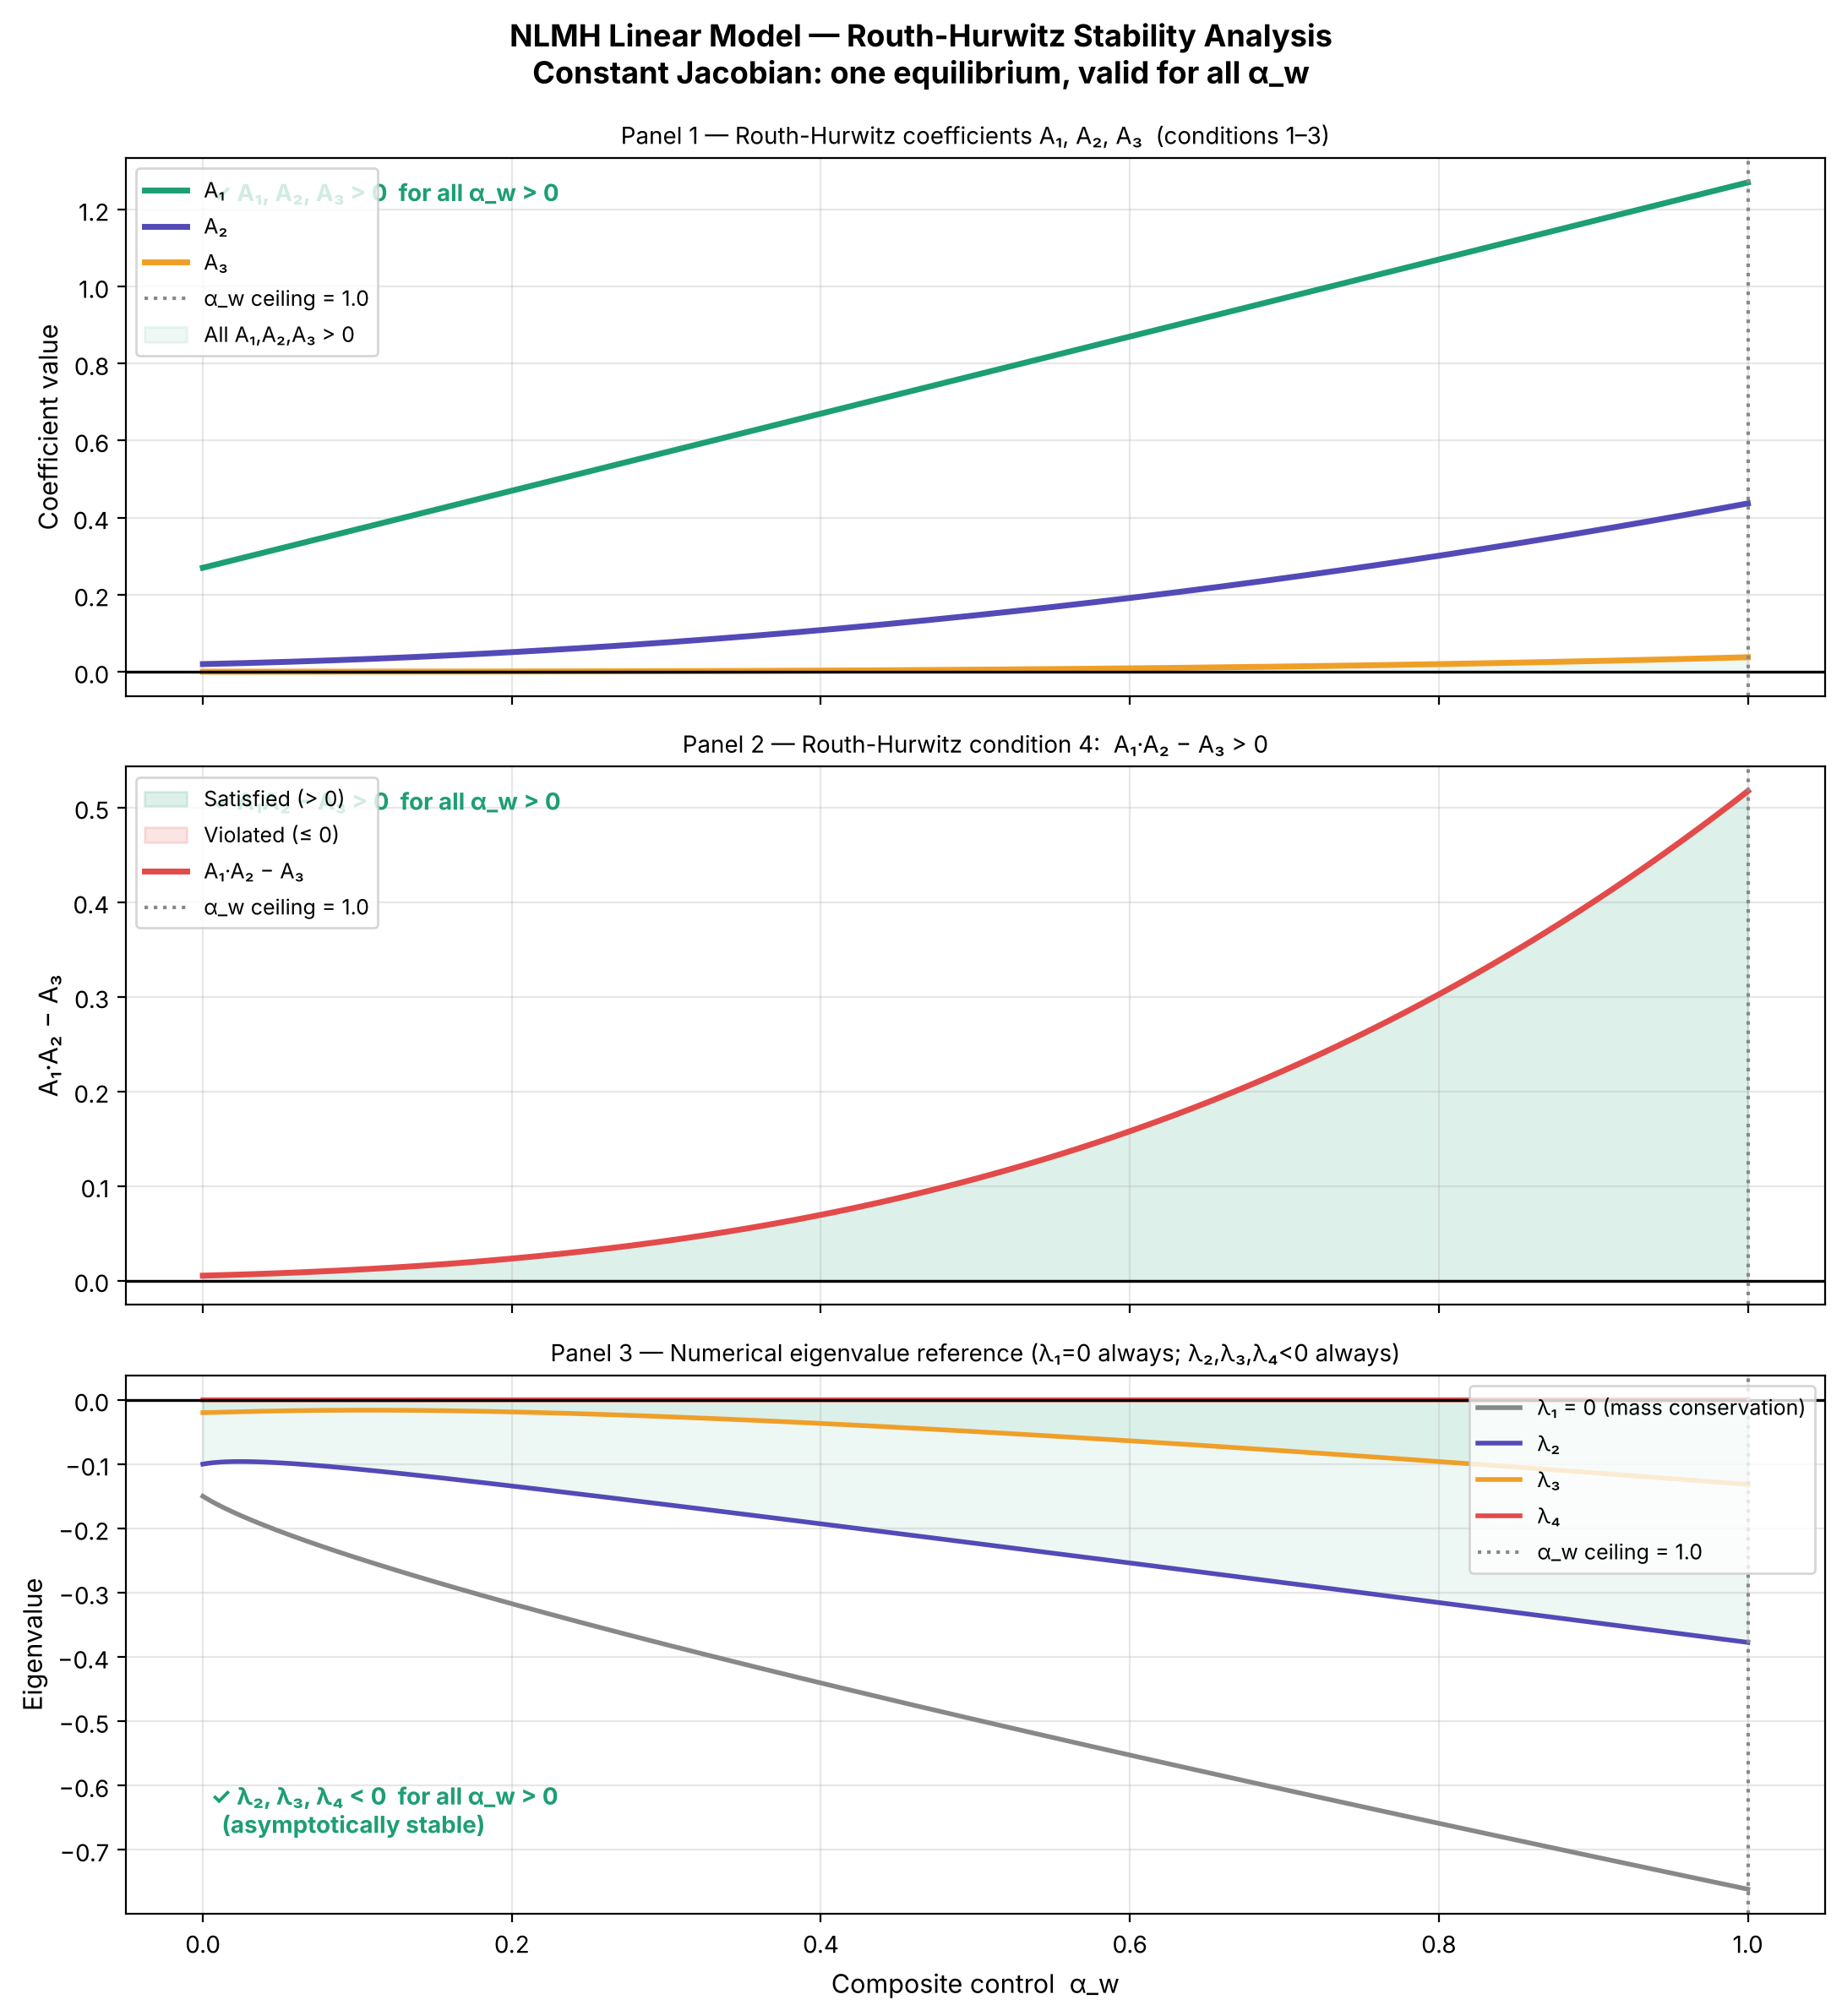


Figure saved: nlmh_stability_linear.png


In [6]:
# =============================================================================
# FIGURE — 3 PANELS (standardized layout)
# Panel 1: A1, A2, A3 combined
# Panel 2: A1*A2 - A3 (condition 4)
# Panel 3: Numerical eigenvalue reference
# =============================================================================
fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
fig.suptitle(
    "NLMH Linear Model — Routh-Hurwitz Stability Analysis\n"
    "Constant Jacobian: one equilibrium, valid for all α_w",
    fontsize=13, fontweight='bold', y=0.99
)

# ── Panel 1: A1, A2, A3 ─────────────────────────────────────────────────────
ax1 = axes[0]
ax1.plot(alpha_w, A1, color='#1D9E75', linewidth=2.5, label='A₁')
ax1.plot(alpha_w, A2, color='#534AB7', linewidth=2.5, label='A₂')
ax1.plot(alpha_w, A3, color='#EF9F27', linewidth=2.5, label='A₃')
ax1.axhline(0, color='black', linewidth=1.2)
ax1.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax1.fill_between(alpha_w, np.minimum(A1, np.minimum(A2, A3)), 0,
                 where=(A1>0)&(A2>0)&(A3>0),
                 color='#1D9E75', alpha=0.08, label='All A₁,A₂,A₃ > 0')
ax1.text(0.05, 0.92, '✓ A₁, A₂, A₃ > 0  for all α_w > 0',
         transform=ax1.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax1.set_ylabel("Coefficient value", fontsize=11)
ax1.set_title("Panel 1 — Routh-Hurwitz coefficients A₁, A₂, A₃  (conditions 1–3)", fontsize=10)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True, alpha=0.3)

# ── Panel 2: A1*A2 - A3 ─────────────────────────────────────────────────────
ax2 = axes[1]
ax2.fill_between(alpha_w, RH4, 0, where=(RH4>0),
                 color='#1D9E75', alpha=0.15, label='Satisfied (> 0)')
ax2.fill_between(alpha_w, RH4, 0, where=(RH4<=0),
                 color='#E24B4A', alpha=0.15, label='Violated (≤ 0)')
ax2.plot(alpha_w, RH4, color='#E24B4A', linewidth=2.5, label='A₁·A₂ − A₃')
ax2.axhline(0, color='black', linewidth=1.2)
ax2.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax2.text(0.05, 0.92, '✓ A₁A₂ − A₃ > 0  for all α_w > 0',
         transform=ax2.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax2.set_ylabel("A₁·A₂ − A₃", fontsize=11)
ax2.set_title("Panel 2 — Routh-Hurwitz condition 4:  A₁·A₂ − A₃ > 0", fontsize=10)
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(True, alpha=0.3)

# ── Panel 3: Numerical eigenvalue reference ──────────────────────────────────
ax3 = axes[2]
eig_arr = np.array([compute_eigenvalues(aw) for aw in alpha_w])
colors_eig = ['#888888', '#534AB7', '#EF9F27', '#E24B4A']
labels_eig = ['λ₁ = 0 (mass conservation)', 'λ₂', 'λ₃', 'λ₄']
for j, (col, lab) in enumerate(zip(colors_eig, labels_eig)):
    ax3.plot(alpha_w, eig_arr[:, j], color=col, linewidth=2.0, label=lab)
ax3.axhline(0, color='black', linewidth=1.2)
ax3.axvline(alpha_max, color='#888888', linewidth=1.5, linestyle=':',
            label=f'α_w ceiling = {alpha_max}')
ax3.fill_between(alpha_w, eig_arr[:, 1], 0, where=(eig_arr[:,1]<0),
                 color='#1D9E75', alpha=0.08)
ax3.fill_between(alpha_w, eig_arr[:, 2], 0, where=(eig_arr[:,2]<0),
                 color='#1D9E75', alpha=0.08)
ax3.fill_between(alpha_w, eig_arr[:, 3], 0, where=(eig_arr[:,3]<0),
                 color='#1D9E75', alpha=0.08)
ax3.text(0.05, 0.15, '✓ λ₂, λ₃, λ₄ < 0  for all α_w > 0\n  (asymptotically stable)',
         transform=ax3.transAxes, color='#1D9E75', fontsize=10, fontweight='bold')
ax3.set_xlabel("Composite control  α_w", fontsize=11)
ax3.set_ylabel("Eigenvalue", fontsize=11)
ax3.set_title("Panel 3 — Numerical eigenvalue reference (λ₁=0 always; λ₂,λ₃,λ₄<0 always)", fontsize=10)
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("nlmh_stability_linear.png", dpi=150)
plt.show()
print("\nFigure saved: nlmh_stability_linear.png")